**Import Required Libraries**


In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

**Read The File Using Pandas**

In [43]:
from google.colab import files

uploaded = files.upload()

Saving autoscout24-germany-dataset 5.csv to autoscout24-germany-dataset 5 (1).csv


**Understanding the data**

In [44]:
df=pd.read_csv('autoscout24-germany-dataset 5.csv')

In [45]:
df.head()


,mileage,make,model,fuel,gear,offerType,price,hp,year
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,2011
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,2011
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,2011
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,2011
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,2011


In [46]:
df.describe()

,mileage,price,hp,year
count,4.640500e+04,4.640500e+04,46376.000000,46405.000000
mean,7.117786e+04,1.657234e+04,132.990987,2016.012951
std,6.262531e+04,1.930470e+04,75.449284,3.155214
min,0.000000e+00,1.100000e+03,1.000000,2011.000000
25%,1.980000e+04,7.490000e+03,86.000000,2013.000000
50%,6.000000e+04,1.099900e+04,116.000000,2016.000000
75%,1.050000e+05,1.949000e+04,150.000000,2019.000000
max,1.111111e+06,1.199900e+06,850.000000,2021.000000


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46405 entries, 0 to 46404
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   mileage    46405 non-null  int64  
 1   make       46405 non-null  object 
 2   model      46262 non-null  object 
 3   fuel       46405 non-null  object 
 4   gear       46223 non-null  object 
 5   offerType  46405 non-null  object 
 6   price      46405 non-null  int64  
 7   hp         46376 non-null  float64
 8   year       46405 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 3.2+ MB


**HANDLING MISSING VALUES**

In [48]:
(df.isnull().mean()*100).sort_values(ascending=False)

,0
gear,0.392199
model,0.308156
hp,0.062493
mileage,0.000000
make,0.000000
fuel,0.000000
offerType,0.000000
price,0.000000
year,0.000000


In [49]:
df['gear']=df['gear'].fillna(value='Unknown')
df['model']=df['model'].fillna(value='Unknown')
df['hp']=df['hp'].fillna(df['hp'].median())

In [50]:
(df.isnull().mean()*100).sort_values(ascending=False)

,0
mileage,0.0
make,0.0
model,0.0
fuel,0.0
gear,0.0
offerType,0.0
price,0.0
hp,0.0
year,0.0


In [51]:
df['age']=2026-df['year']
df.drop('year',axis=1,inplace=True)
df.head()

,mileage,make,model,fuel,gear,offerType,price,hp,age
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,15
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,15
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,15
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,15
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,15


**EDA**

<Axes: >

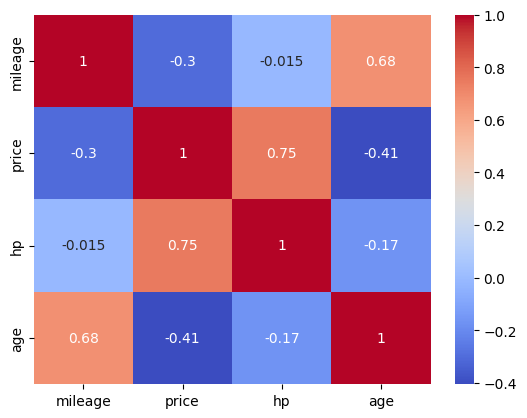

In [52]:
sns.heatmap(data=df.corr(numeric_only=True),cmap='coolwarm',annot=True)

**DATA VISUALIZATION**

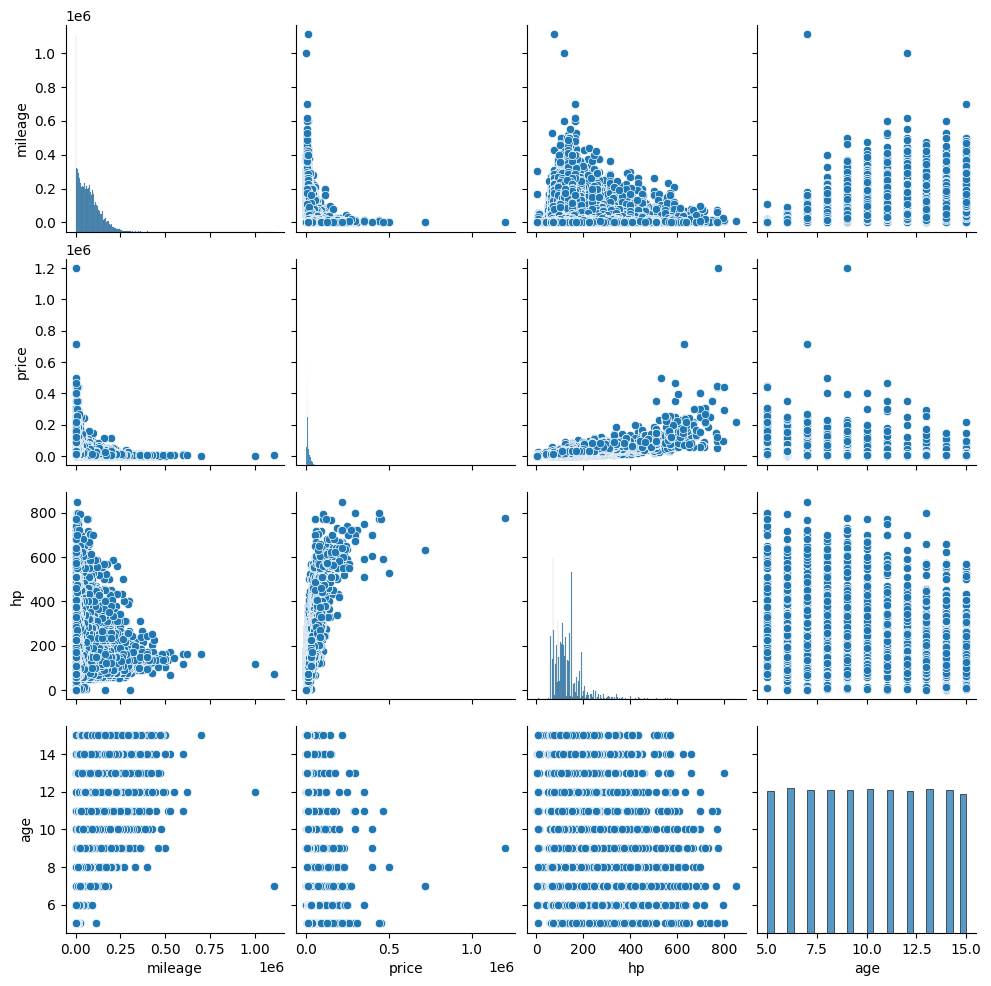

In [53]:
sns.pairplot(data=df)

<Axes: xlabel='age', ylabel='price'>

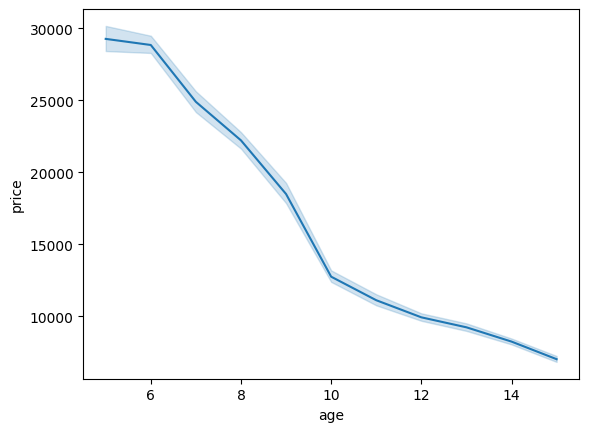

In [54]:
sns.lineplot(x='age',y='price',data=df)

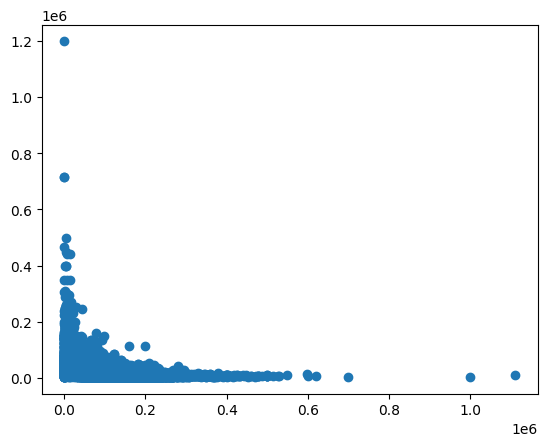

In [55]:
plt.scatter(x=df['mileage'],y=df['price'])

**TRAIN TEST SPLIT**

In [56]:
from sklearn.model_selection import train_test_split


In [57]:
x=df.drop(columns='price')
y=df['price']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=40)

**FEATURE ENGINEERING**

In [58]:
x_train = pd.get_dummies(x_train, dtype=int)
x_test = pd.get_dummies(x_test, dtype=int)

x_test = x_test.reindex(
    columns=x_train.columns,
    fill_value=0
)



**LINEAR REGRESSION**

In [59]:
from sklearn.linear_model import LinearRegression
lm=LinearRegression()
lm.fit(x_train,y_train)
pred=lm.predict(x_test)

In [60]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
dic_1 = {
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": root_mean_squared_error(y_test, pred),
    "R2": r2_score(y_test, pred)
}


**DECISION TREEE**


In [61]:
from sklearn.tree import DecisionTreeRegressor
dtree=DecisionTreeRegressor()
dtree.fit(x_train,y_train)
pred_2=dtree.predict(x_test)

In [62]:
print("MAE",mean_absolute_error(y_test,pred_2))
print("RMSE",root_mean_squared_error(y_test,pred_2))
print("R2",r2_score(y_test,pred_2))

MAE 2228.0584207109614
RMSE 5269.154631362422
R2 0.9028132720761328


In [63]:
dic_2={"MAE":mean_absolute_error(y_test,pred_2),
"RMSE":root_mean_squared_error(y_test,pred_2),
"R2":r2_score(y_test,pred_2)}
dic_2


{'MAE': 2228.0584207109614,
 'RMSE': 5269.154631362422,
 'R2': 0.9028132720761328}

**RANDOM FOREST**

In [64]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=3)
rf.fit(x_train,y_train)
pred_3=rf.predict(x_test)

In [65]:
dic_3 = {
    "MAE": mean_absolute_error(y_test, pred_3),
    "RMSE": root_mean_squared_error(y_test, pred_3),
    "R2": r2_score(y_test, pred_3)
}
dic_3

{'MAE': 2077.017674368856, 'RMSE': 4931.281416074622, 'R2': 0.9148774455949032}

**MODEL PERFORMANCE**

In [66]:


# Combine the metric dictionaries into a single DataFrame
compare = pd.DataFrame(
    data=[dic_1, dic_2, dic_3],
    index=["Linear Regression", "Decision Tree", "Random Forest"]
)

# Display the comparison table
print(compare)


                           MAE         RMSE        R2
Linear Regression  2841.896044  5683.192706  0.886940
Decision Tree      2228.058421  5269.154631  0.902813
Random Forest      2077.017674  4931.281416  0.914877


**BASELINE MODEL AND COMPARISON**

In [67]:
from sklearn.dummy import DummyRegressor


# Baseline model: predict the median training price
baseline = DummyRegressor(strategy='median')
baseline.fit(x_train, y_train)

# Predict on the test set
baseline_pred = baseline.predict(x_test)

# Evaluate baseline
dic_baseline = {
    'MAE': mean_absolute_error(y_test, baseline_pred),
    'RMSE':root_mean_squared_error(y_test, baseline_pred),
    'R2': r2_score(y_test, baseline_pred)
}

# Compare all models
compare = pd.DataFrame(
    [dic_baseline, dic_1, dic_2, dic_3],
    index=['Baseline (Median)', 'Linear Regression',
           'Decision Tree', 'Random Forest']
)

print(compare.round(6))

                           MAE          RMSE        R2
Baseline (Median)  8888.803685  17741.662114 -0.101828
Linear Regression  2841.896044   5683.192706  0.886940
Decision Tree      2228.058421   5269.154631  0.902813
Random Forest      2077.017674   4931.281416  0.914877


**CHECK for OVERFITTING**


In [68]:
from sklearn.metrics import mean_absolute_error

# Make predictions on training and test data
lr_train_pred = lm.predict(x_train)
lr_test_pred = lm.predict(x_test)

dt_train_pred = dtree.predict(x_train)
dt_test_pred = dtree.predict(x_test)

rf_train_pred = rf.predict(x_train)
rf_test_pred = rf.predict(x_test)

# Compare training and test errors
overfit_check = pd.DataFrame({
    'Train MAE': [
        mean_absolute_error(y_train, lr_train_pred),
        mean_absolute_error(y_train, dt_train_pred),
        mean_absolute_error(y_train, rf_train_pred)
    ],
    'Test MAE': [
        mean_absolute_error(y_test, lr_test_pred),
        mean_absolute_error(y_test, dt_test_pred),
        mean_absolute_error(y_test, rf_test_pred)
    ]
}, index=['Linear Regression', 'Decision Tree', 'Random Forest'])

overfit_check['MAE Gap'] = (
    overfit_check['Test MAE'] - overfit_check['Train MAE']
)

print(overfit_check.round(2))

                   Train MAE  Test MAE  MAE Gap
Linear Regression    2668.45   2841.90   173.44
Decision Tree          38.95   2228.06  2189.11
Random Forest         929.67   2077.02  1147.35


Since Decision Tree has more MAE Gap the model is likely to be overfitted hence we are gonna impose some restrictions such as max_depth and tune the model for more reliable output.

**Check for max_depth value using Grid search**

In [69]:
from sklearn.model_selection import GridSearchCV
param_grid = {'max_depth': [5, 10, 15, 20, 25, 30]}
grid_search = GridSearchCV(DecisionTreeRegressor(), param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(x_train, y_train)
grid_pred=grid_search.predict(x_test)
print("Best depth:", grid_search.best_params_)
print("Best cross-validation MAE:", -grid_search.best_score_)

Best depth: {'max_depth': 20}
Best cross-validation MAE: 99278797.07831797


**we can see that the model performed best when depth was 20 ,so we are gonna use max_depth=20 and fine tune the model for better performance**

In [81]:
dtree2=DecisionTreeRegressor(max_depth=20)
dtree2.fit(x_train,y_train)
pred_2_2=dtree2.predict(x_test)

In [82]:
dic_2_2={"MAE":mean_absolute_error(y_test,pred_2_2),
"RMSE":root_mean_squared_error(y_test,pred_2_2),
"R2":r2_score(y_test,pred_2_2)}
dic_2_2

{'MAE': 2200.404752038916, 'RMSE': 5219.674069527226, 'R2': 0.9046299865991372}

**FINAL PERFORMANCE COMPARISON OF ALL MODELS**

In [83]:
compare2 = pd.DataFrame(
    [dic_baseline, dic_1, dic_2,dic_2_2,dic_3],
    index=['Baseline (Median)', 'Linear Regression',
           'Decision Tree','Decision Tree fine tuned', 'Random Forest']
)

print(compare2.round(6))

                                  MAE          RMSE        R2
Baseline (Median)         8888.803685  17741.662114 -0.101828
Linear Regression         2841.896044   5683.192706  0.886940
Decision Tree             2228.058421   5269.154631  0.902813
Decision Tree fine tuned  2200.404752   5219.674070  0.904630
Random Forest             2077.017674   4931.281416  0.914877


**DEEP LEARNING**

In [84]:
from  tensorflow.keras.models import Sequential

In [85]:
from tensorflow.keras.layers import Dense

In [86]:
model = Sequential([Dense(3, activation='relu'),
                    Dense(5,activation='relu'),
                    Dense(1,activation='relu')])

In [87]:
model.compile(optimizer='adam',loss='mean_squared_error')
model.fit(x=x_train,y=y_train,epochs=10)
pred_5=model.predict(x_test)

Epoch 1/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 670534400.0000
Epoch 2/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670534272.0000
Epoch 3/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 670534464.0000
Epoch 4/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 670534016.0000
Epoch 5/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670534144.0000
Epoch 6/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670535296.0000
Epoch 7/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670534592.0000
Epoch 8/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 670534400.0000
Epoch 9/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670534144.0000
Epoch 10/10
1161/1161 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 670534848.0000
291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [88]:
pred_5

array([[0.],
       [0.],
       [0.],
       ...,
       [0.],
       [0.],
       [0.]], dtype=float32)

In [89]:
import numpy as np

# Flatten the deep learning predictions to a 1D array
pred_5_flat = pred_5.flatten()

# Calculate evaluation metrics
dic_5 = {
    "MAE": mean_absolute_error(y_test, pred_5_flat),
    "RMSE": root_mean_squared_error(y_test, pred_5_flat),
    "R2": r2_score(y_test, pred_5_flat)
}

# Display the Deep Learning metrics
print("Deep Learning Model Evaluation:")
for metric, value in dic_5.items():
    print(f"{metric}: {value:.6f}")

Deep Learning Model Evaluation:
MAE: 16392.498047
RMSE: 23545.503906
R2: -0.940623


In [90]:
# Compare all models including the new Deep Learning model
compare_final = pd.DataFrame(
    [dic_baseline, dic_1, dic_2, dic_2_2, dic_3, dic_5],
    index=['Baseline (Median)', 'Linear Regression',
           'Decision Tree', 'Decision Tree fine tuned', 'Random Forest', 'Deep Learning']
)

display(compare_final.round(6))

,MAE,RMSE,R2
Baseline (Median),8888.803685,17741.662114,-0.101828
Linear Regression,2841.896044,5683.192706,0.886940
Decision Tree,2228.058421,5269.154631,0.902813
Decision Tree fine tuned,2200.404752,5219.674070,0.904630
Random Forest,2077.017674,4931.281416,0.914877
Deep Learning,16392.498047,23545.503906,-0.940623


### Improving the Deep Learning Model
We will use `StandardScaler` on the input features and remove the ReLU activation from the final output layer.

In [91]:
from sklearn.preprocessing import StandardScaler

# Scale the features for the Neural Network
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Rebuild the model: remove activation from final Dense(1) layer
model_v2 = Sequential([
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)  # Linear activation for regression
])

# Compile and train with a more appropriate learning rate
model_v2.compile(optimizer='adam', loss='mean_squared_error')
model_v2.fit(x=x_train_scaled, y=y_train, epochs=30, batch_size=32, validation_split=0.1)

# Predict and evaluate
pred_5_v2 = model_v2.predict(x_test_scaled).flatten()

dic_5_v2 = {
    "MAE": mean_absolute_error(y_test, pred_5_v2),
    "RMSE": root_mean_squared_error(y_test, pred_5_v2),
    "R2": r2_score(y_test, pred_5_v2)
}

# Compare all models including the updated Deep Learning model
compare_final_v2 = pd.DataFrame(
    [dic_baseline, dic_1, dic_2, dic_2_2, dic_3, dic_5_v2],
    index=['Baseline (Median)', 'Linear Regression',
           'Decision Tree', 'Decision Tree fine tuned', 'Random Forest', 'Deep Learning (Scaled)']
)

display(compare_final_v2.round(6))

Epoch 1/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 512542880.0000 - val_loss: 273313248.0000
Epoch 2/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 325243136.0000 - val_loss: 223949152.0000
Epoch 3/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 282212064.0000 - val_loss: 196919392.0000
Epoch 4/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 254749792.0000 - val_loss: 178713472.0000
Epoch 5/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 233278928.0000 - val_loss: 163336272.0000
Epoch 6/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 214472896.0000 - val_loss: 149823232.0000
Epoch 7/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 197700192.0000 - val_loss: 137292928.0000
Epoch 8/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 182803008.0000 - val_loss: 123481960.0000
Epoch 9/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 168173632.0000 - val_loss: 109317616.0000
Epoch 10/30
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 1

,MAE,RMSE,R2
Baseline (Median),8888.803685,17741.662114,-0.101828
Linear Regression,2841.896044,5683.192706,0.886940
Decision Tree,2228.058421,5269.154631,0.902813
Decision Tree fine tuned,2200.404752,5219.674070,0.904630
Random Forest,2077.017674,4931.281416,0.914877
Deep Learning (Scaled),2587.787598,25687.345703,-1.309742
